# Distributed queue between a producer and a consumer

A ray.util.queue.Queue connects a remote producer task to a remote consumer task. The builder writes both tasks for you.

**When to use it.** Hand-off between stages that run at different speeds, or streaming work items to a pool of consumers.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

> **Experimental.** The builder lists a node in this graph in its *Experimental* section, so the node may change in later releases of the builder. The generated code ran on Ray 2.55.1.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

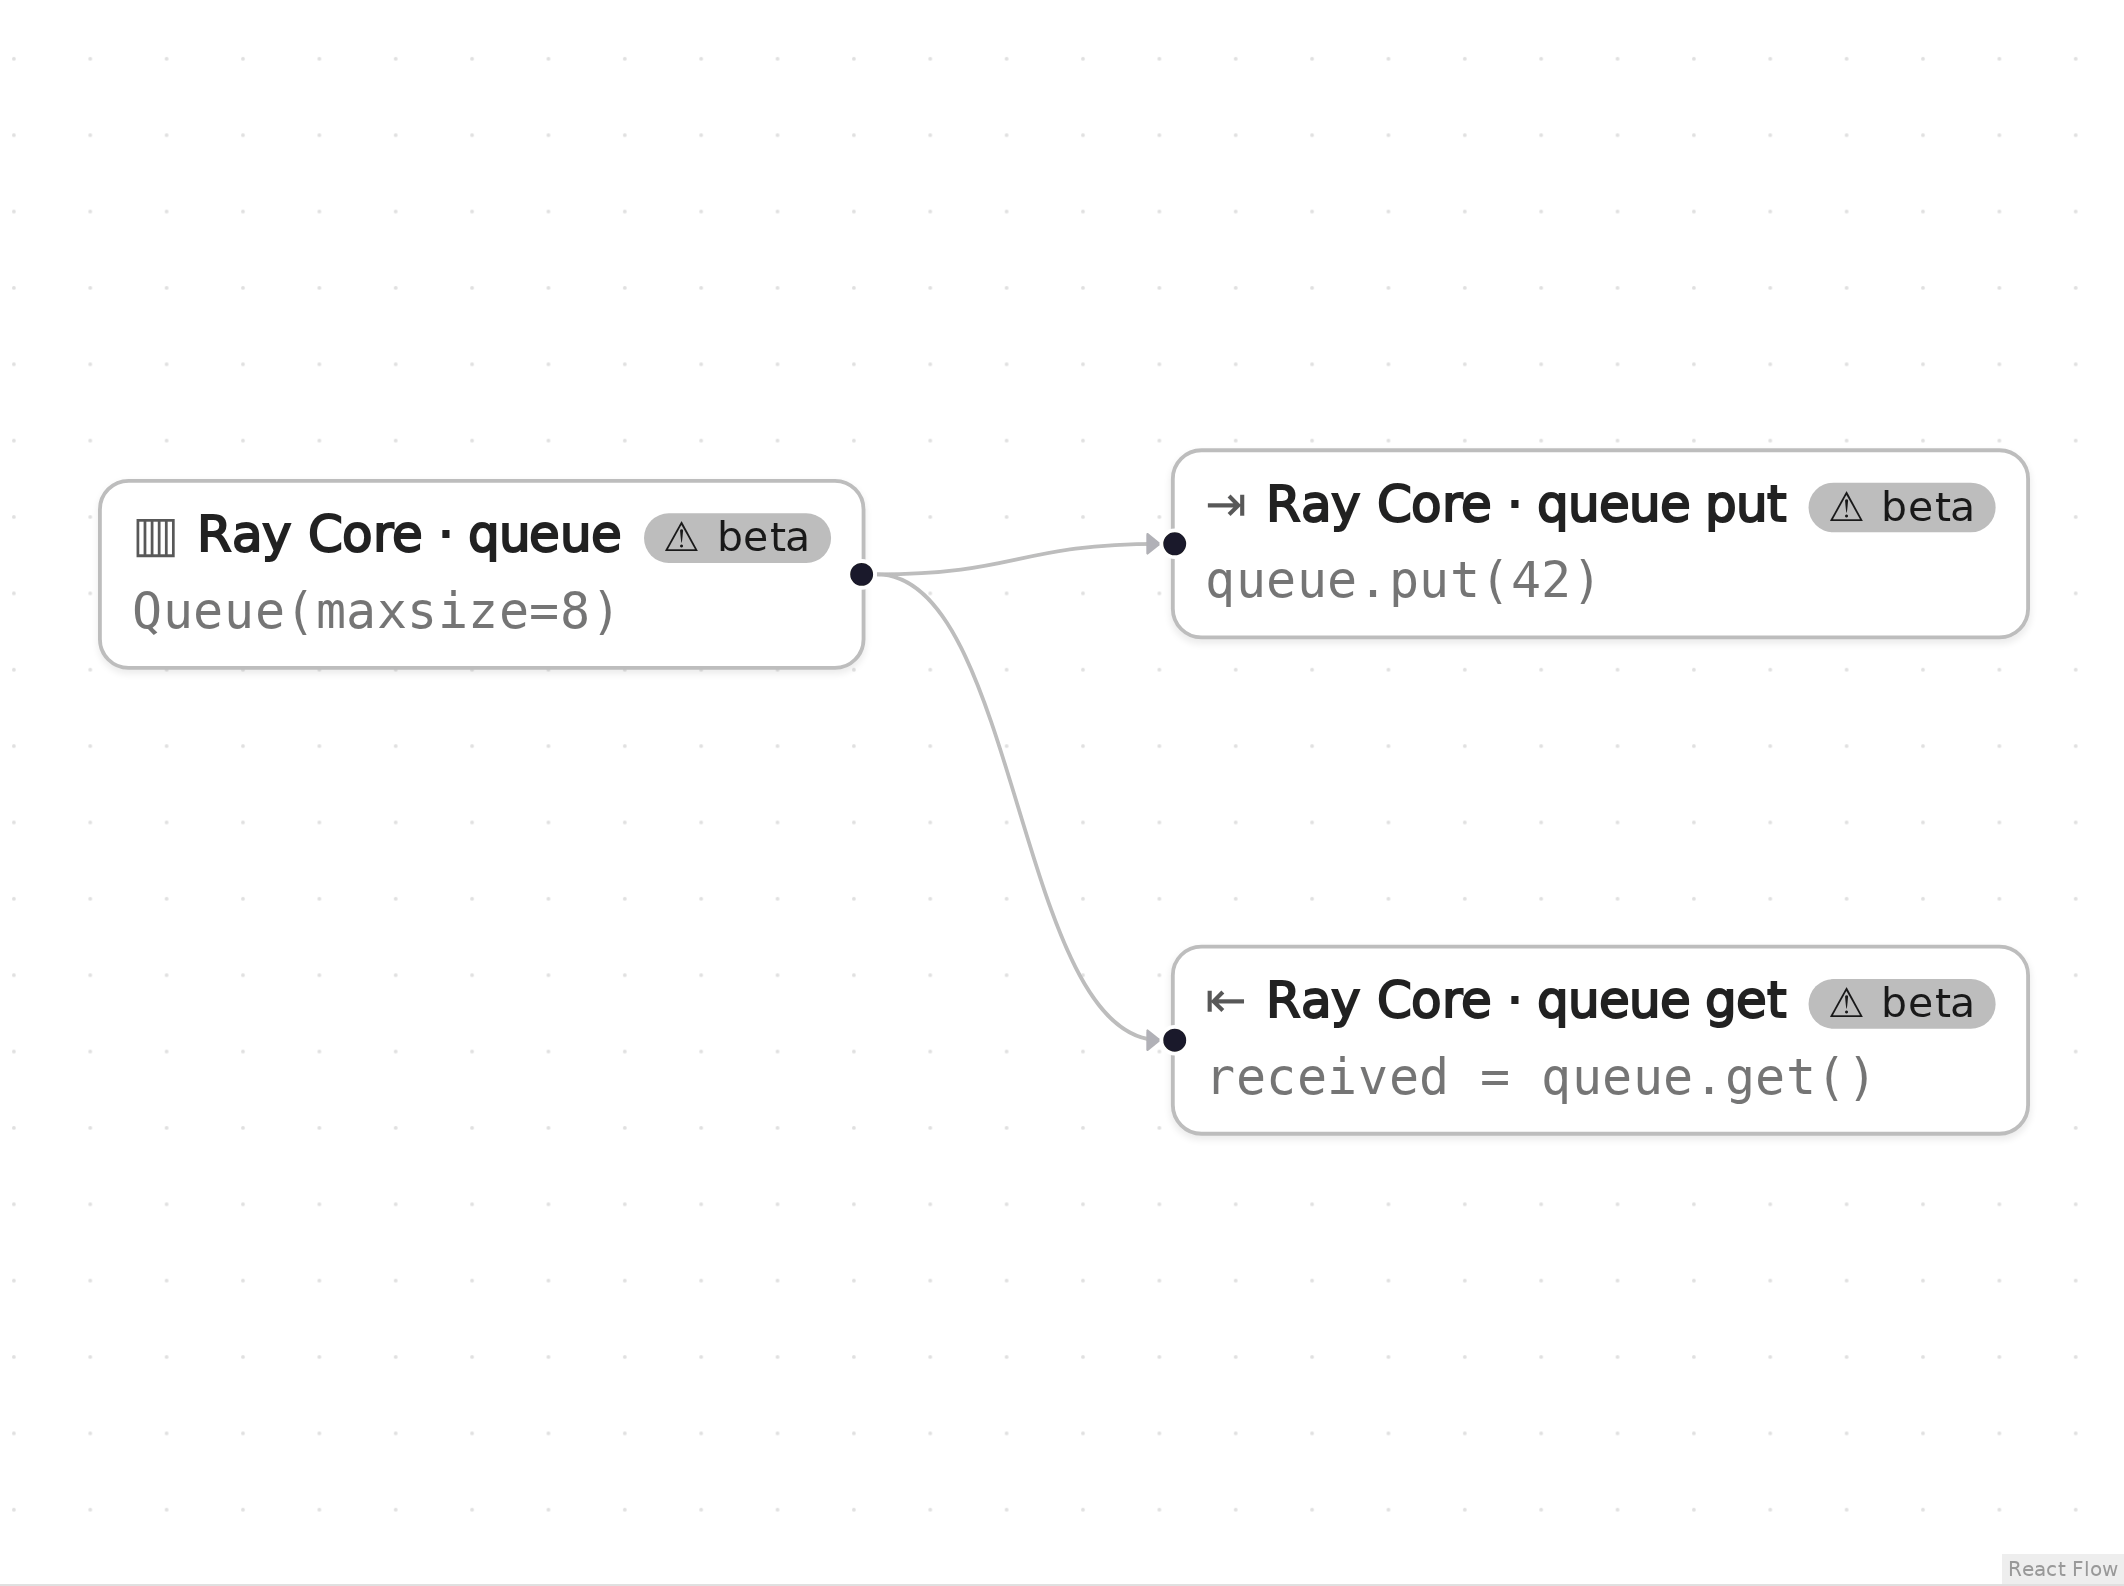

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

This pattern needs no user functions: the builder writes the producer and the consumer tasks, and the producer puts the literal value 42 on the queue.

## Generated code

This is the cell the visual builder generated from the graph above.

In [2]:
# Generated with Eugo's visual Ray builder

import ray
from ray.util.queue import Queue

if not ray.is_initialized():
    ray.init()

_queue_q1 = Queue(maxsize=8)
@ray.remote
def _qput_q2(q, item):
    q.put(item)
_qput_q2.remote(_queue_q1, 42)
@ray.remote
def _qget_q3(q):
    return q.get()
received = ray.get(_qget_q3.remote(_queue_q1))

## Check the result

The cell below checks that the generated code did what the graph describes.

In [3]:
assert received == 42, received
print("received =", received)

received = 42


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–4 and 6–7)

```python
# Generated with Eugo's visual Ray builder
...
import ray
from ray.util.queue import Queue
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Queue (beta)** (node `q1`, line 9)

```python
_queue_q1 = Queue(maxsize=8)
```

Creates the queue (an actor under the hood) with room for 8 items.

**Queue put (beta)** (node `q2`, lines 10–13)

```python
@ray.remote
def _qput_q2(q, item):
    q.put(item)
_qput_q2.remote(_queue_q1, 42)
```

A generated remote task that puts 42 on the queue.

**Queue get (beta)** (node `q3`, lines 14–17)

```python
@ray.remote
def _qget_q3(q):
    return q.get()
received = ray.get(_qget_q3.remote(_queue_q1))
```

A generated remote task that blocks until an item arrives. The consumer is submitted after the producer, but the two tasks can run in either order: if the consumer starts first, q.get() waits for the producer's item.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [4]:
ray.shutdown()